# Retail Sales Forecasting and Customer Analytics
## Exploratory Data Analysis

### Purpose

The purpose of this analysis is to explore the prepared retail dataset and identify important sales, product and customer purchasing patterns.

The analysis will focus on:

- overall sales performance;
- sales trends over time;
- product category performance;
- customer purchasing behaviour;
- geographical sales patterns; and
- patterns that may influence the later customer segmentation and sales forecasting stages.

The analysis uses the prepared datasets created during the data cleaning stage. Delivered orders will be used for sales analysis to avoid treating cancelled, unavailable or incomplete orders as completed sales.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
project_path = Path.cwd().parent
cleaned_data_path = project_path / "02_Cleaned_Data"

# Load prepared transaction dataset
transactions = pd.read_csv(
    cleaned_data_path / "transactions_clean.csv"
)

print("Dataset loaded successfully.")
print("Rows:", len(transactions))
print("Columns:", len(transactions.columns))

Dataset loaded successfully.
Rows: 110197
Columns: 27


In [2]:
# Check dataset structure
transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 110197 entries, 0 to 110196
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       110197 non-null  str    
 1   order_item_id                  110197 non-null  int64  
 2   product_id                     110197 non-null  str    
 3   seller_id                      110197 non-null  str    
 4   shipping_limit_date            110197 non-null  str    
 5   price                          110197 non-null  float64
 6   freight_value                  110197 non-null  float64
 7   customer_id                    110197 non-null  str    
 8   order_status                   110197 non-null  str    
 9   order_purchase_timestamp       110197 non-null  str    
 10  order_approved_at              110182 non-null  str    
 11  order_delivered_carrier_date   110195 non-null  str    
 12  order_delivered_customer_date  110189 non

In [3]:
# Convert date columns to datetime format
date_columns = [
    "shipping_limit_date",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "purchase_date"
]

for column in date_columns:
    transactions[column] = pd.to_datetime(
        transactions[column],
        errors="coerce"
    )

print("Date conversion completed.")

print(
    transactions[
        ["order_purchase_timestamp", "purchase_date"]
    ].dtypes
)

Date conversion completed.
order_purchase_timestamp    datetime64[us]
purchase_date               datetime64[us]
dtype: object


In [4]:
# Overall delivered sales summary

total_sales = transactions["sales_value"].sum()
total_orders = transactions["order_id"].nunique()
total_items = len(transactions)
total_customers = transactions["customer_unique_id"].nunique()
total_products = transactions["product_id"].nunique()

average_order_value = total_sales / total_orders

print("Overall Delivered Sales Summary")
print("--------------------------------")
print("Total product sales:", round(total_sales, 2))
print("Total delivered orders:", total_orders)
print("Total items sold:", total_items)
print("Unique customers:", total_customers)
print("Unique products sold:", total_products)
print("Average product sales per order:", round(average_order_value, 2))

Overall Delivered Sales Summary
--------------------------------
Total product sales: 13221498.11
Total delivered orders: 96478
Total items sold: 110197
Unique customers: 93358
Unique products sold: 32216
Average product sales per order: 137.04


In [5]:
# Aggregate delivered product sales by month
monthly_sales = (
    transactions
    .groupby("purchase_month")
    .agg(
        product_sales=("sales_value", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .reset_index()
)

monthly_sales["product_sales"] = monthly_sales["product_sales"].round(2)

print(monthly_sales)

   purchase_month  product_sales  total_orders  items_sold
0         2016-09         134.97             1           3
1         2016-10       40325.11           265         313
2         2016-12          10.90             1           1
3         2017-01      111798.36           750         913
4         2017-02      234223.40          1653        1858
5         2017-03      359198.85          2546        2897
6         2017-04      340669.68          2303        2569
7         2017-05      489338.25          3546        4004
8         2017-06      421923.37          3135        3489
9         2017-07      481604.52          3872        4416
10        2017-08      554699.70          4193        4797
11        2017-09      607399.67          4150        4737
12        2017-10      648247.65          4478        5214
13        2017-11      987765.37          7289        8475
14        2017-12      726033.19          5513        6187
15        2018-01      924645.00          7069        80

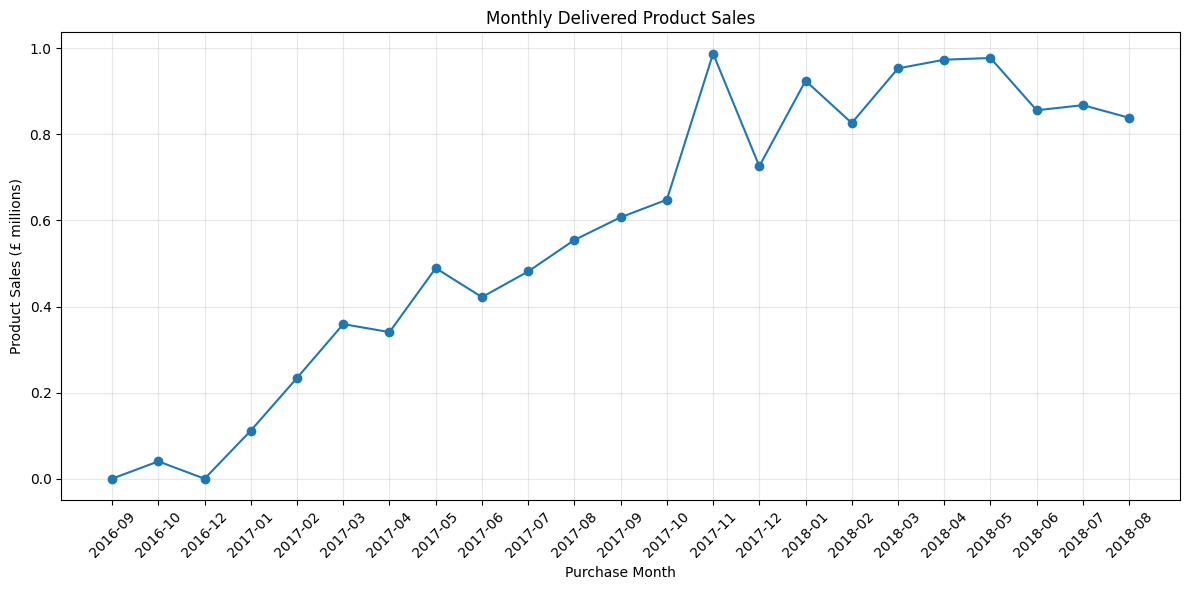

In [ ]:
# Visualise monthly delivered product sales

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["purchase_month"],
    monthly_sales["product_sales"] / 1_000_000,
    marker="o"
)

plt.title("Monthly Delivered Product Sales")
plt.xlabel("Purchase Month")
plt.ylabel("Product Sales (R$ millions)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Monthly Sales Trend

The monthly sales analysis shows an overall increase in delivered product sales across the main period of the dataset. Sales increased during 2017, with a noticeable peak in November 2017 at approximately R$0.99 million. Monthly sales remained relatively high during 2018, reaching approximately R$0.97–R$0.98 million in April and May before decreasing slightly between June and August.

The earliest months should be interpreted carefully because the 2016 data is sparse and does not represent a complete year. For example, September and December 2016 contain only one delivered order each, while November 2016 has no delivered transactions in the prepared dataset. Therefore, these months should not be used to make direct year-on-year performance conclusions.

The pattern suggests that time is an important factor in sales performance and supports further investigation of trends and seasonality before developing the forecasting models.

In [8]:
# Analyse product category performance

category_performance = (
    transactions
    .groupby("category_name_clean")
    .agg(
        product_sales=("sales_value", "sum"),
        items_sold=("order_item_id", "count"),
        total_orders=("order_id", "nunique")
    )
    .reset_index()
    .sort_values("product_sales", ascending=False)
)

category_performance["product_sales"] = (
    category_performance["product_sales"].round(2)
)

print("Top 10 Product Categories by Sales")
print(
    category_performance[
        ["category_name_clean", "product_sales", "items_sold", "total_orders"]
    ].head(10)
)

Top 10 Product Categories by Sales
      category_name_clean  product_sales  items_sold  total_orders
44          health_beauty     1233131.72        9465          8647
73          watches_gifts     1166176.98        5859          5495
8          bed_bath_table     1023434.76       10953          9272
68         sports_leisure      954852.55        8431          7530
16  computers_accessories      888724.61        7644          6530
40        furniture_decor      711927.69        8160          6307
50             housewares      615628.69        6795          5743
21             cool_stuff      610204.10        3718          3559
6                    auto      578966.65        4140          3810
72                   toys      471286.48        4030          3804


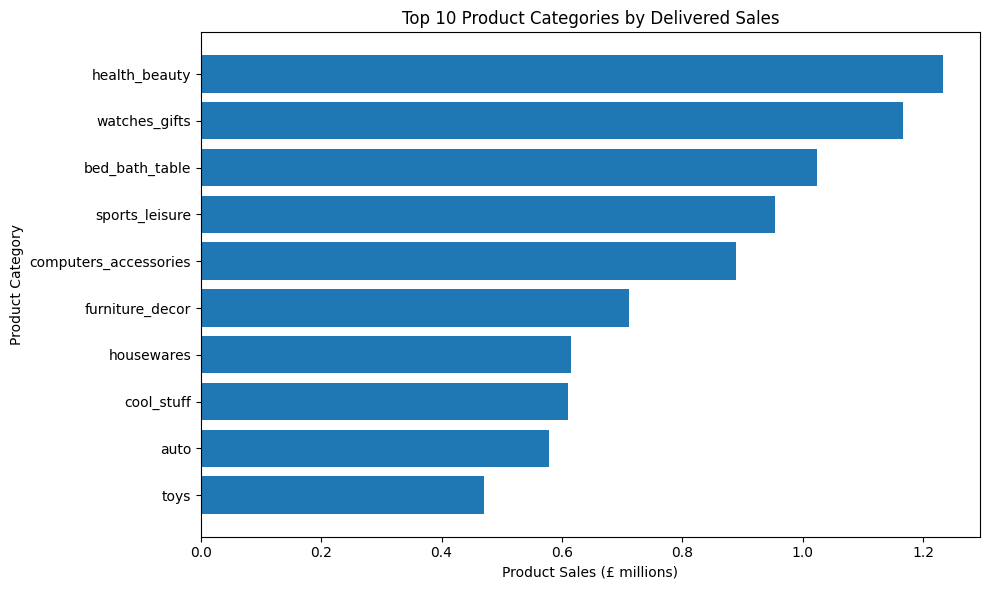

In [9]:
# Select the top 10 categories by product sales
top_categories = category_performance.head(10).copy()

# Convert sales to £ millions for clearer presentation
top_categories["sales_millions"] = (
    top_categories["product_sales"] / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories["category_name_clean"],
    top_categories["sales_millions"]
)

plt.title("Top 10 Product Categories by Delivered Sales")
plt.xlabel("Product Sales (£ millions)")
plt.ylabel("Product Category")

# Highest-selling category at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Product Category Performance

The product category analysis shows that sales are not distributed equally across categories. Health and beauty generated the highest delivered product sales at approximately £1.23 million, followed by watches and gifts at approximately £1.17 million and bed, bath and table at approximately £1.02 million.

However, sales value does not always follow the number of items sold. Bed, bath and table had the highest number of items sold among the top ten categories, with 10,953 items, but it ranked third by sales value. In comparison, watches and gifts generated the second-highest sales value from only 5,859 items. This suggests that differences in product prices are also important when evaluating category performance.

These results show that category performance should be assessed using more than one measure. Sales value, number of items sold and number of orders can provide different information and will therefore be considered in the later dashboard and business analysis.

In [10]:
# Create customer-level purchasing summary

customer_summary = (
    transactions
    .groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        items_purchased=("order_item_id", "count"),
        total_spend=("sales_value", "sum"),
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

customer_summary["total_spend"] = customer_summary["total_spend"].round(2)

print("Customer Summary")
print("----------------")
print("Customers:", len(customer_summary))
print("\nOrders per customer:")
print(customer_summary["total_orders"].describe())

print("\nCustomer spend:")
print(customer_summary["total_spend"].describe())

Customer Summary
----------------
Customers: 93358

Orders per customer:
count    93358.000000
mean         1.033420
std          0.209097
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         15.000000
Name: total_orders, dtype: float64

Customer spend:
count    93358.000000
mean       141.621480
std        215.694014
min          0.850000
25%         47.650000
50%         89.730000
75%        154.737500
max      13440.000000
Name: total_spend, dtype: float64


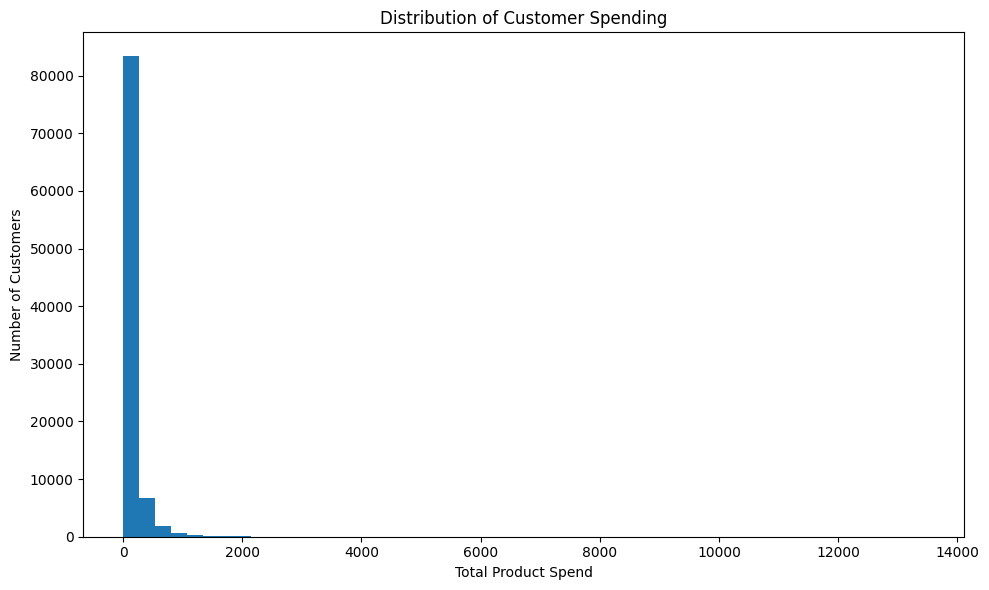

In [11]:
# Visualise customer spending distribution

plt.figure(figsize=(10, 6))

plt.hist(
    customer_summary["total_spend"],
    bins=50
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Total Product Spend")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()


In [12]:
# Examine customer spending percentiles

spend_percentiles = customer_summary["total_spend"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Customer Spending Percentiles")
print("-----------------------------")
print(spend_percentiles)

Customer Spending Percentiles
-----------------------------
0.50      89.7300
0.75     154.7375
0.90     279.9900
0.95     419.8090
0.99    1004.9900
Name: total_spend, dtype: float64


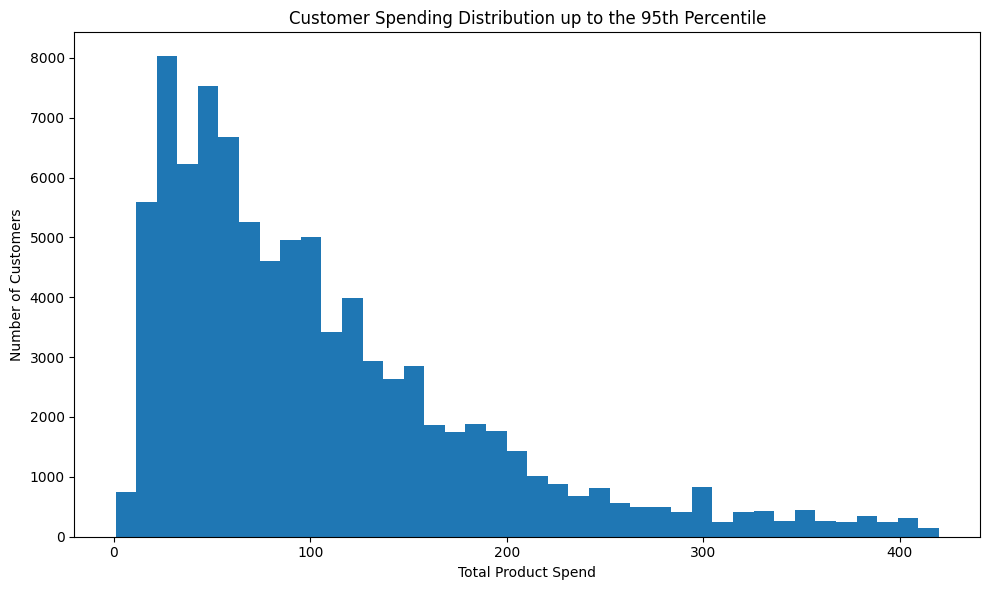

In [13]:
# Visualise spending distribution for the majority of customers

spend_95 = customer_summary["total_spend"].quantile(0.95)

plt.figure(figsize=(10, 6))

plt.hist(
    customer_summary.loc[
        customer_summary["total_spend"] <= spend_95,
        "total_spend"
    ],
    bins=40
)

plt.title("Customer Spending Distribution up to the 95th Percentile")
plt.xlabel("Total Product Spend")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()

### Customer Purchasing Behaviour

The customer-level analysis identified 93,358 customers with delivered orders. Purchasing frequency is low, with a median of one order per customer and 75% of customers also having only one order. This is consistent with the earlier SQL analysis, which showed that repeat purchasing represents a relatively small proportion of customers.

Customer spending is strongly right-skewed. The median total product spend was 89.73, compared with a mean of 141.62, while the maximum customer spend was 13,440. The percentile analysis showed that 95% of customers spent no more than 419.81 and 99% spent no more than 1,004.99.

The second distribution chart focuses on customers up to the 95th percentile to make the spending pattern of the majority of customers easier to observe. Customers above this level were not removed from the dataset because the previous data validation did not provide evidence that these higher values were errors.

These findings are important for the later customer segmentation stage. The low level of repeat purchasing means that frequency may provide limited separation between many customers, while the skewed monetary values may require transformation or scaling before applying clustering or other segmentation techniques.

In [14]:
# Classify customers by purchasing frequency

customer_summary["customer_type"] = np.where(
    customer_summary["total_orders"] > 1,
    "Repeat Customer",
    "One-time Customer"
)

customer_type_summary = (
    customer_summary["customer_type"]
    .value_counts()
    .rename_axis("customer_type")
    .reset_index(name="customers")
)

customer_type_summary["percentage"] = (
    customer_type_summary["customers"]
    / customer_type_summary["customers"].sum()
    * 100
).round(2)

print(customer_type_summary)

       customer_type  customers  percentage
0  One-time Customer      90557        97.0
1    Repeat Customer       2801         3.0


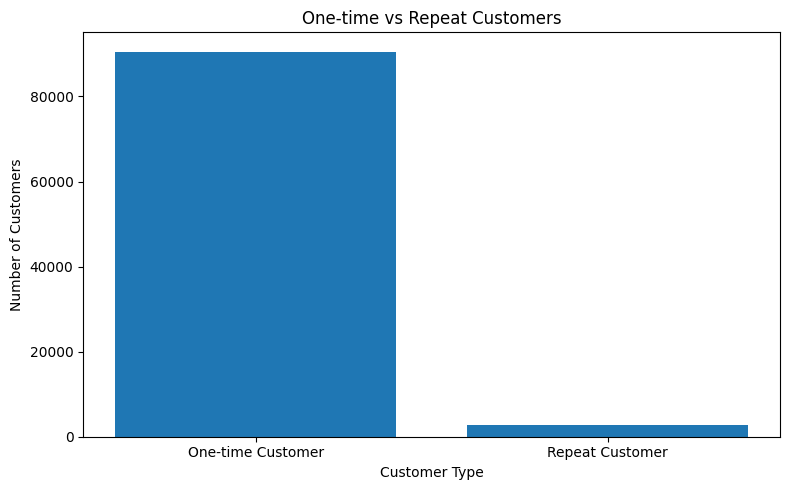

In [15]:
# Visualise one-time and repeat customers

plt.figure(figsize=(8, 5))

plt.bar(
    customer_type_summary["customer_type"],
    customer_type_summary["customers"]
)

plt.title("One-time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.show()

### One-time and Repeat Customers

The analysis shows that 90,557 customers (97.0%) made only one delivered order, while 2,801 customers (3.0%) made more than one delivered order. This confirms that repeat purchasing is uncommon within the available dataset.

This result is important for customer segmentation because purchase frequency provides limited variation across most customers. A traditional RFM approach relies on recency, frequency and monetary value, but frequency may not strongly differentiate customers when the large majority have only one order. Therefore, the segmentation method should be selected and evaluated carefully rather than assuming that standard RFM scoring will provide meaningful customer groups.

From a business perspective, the low observed repeat-purchase rate may also indicate an area for further investigation. However, the dataset alone does not establish why customers did not purchase again, so no conclusion about customer satisfaction, loyalty or retention should be made from this result alone.

In [16]:
# Analyse delivered sales by customer state

state_performance = (
    transactions
    .groupby("customer_state")
    .agg(
        product_sales=("sales_value", "sum"),
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_unique_id", "nunique")
    )
    .reset_index()
    .sort_values("product_sales", ascending=False)
)

state_performance["product_sales"] = (
    state_performance["product_sales"].round(2)
)

print("Top 10 Customer States by Product Sales")
print(
    state_performance[
        ["customer_state", "product_sales", "total_orders", "unique_customers"]
    ].head(10)
)

Top 10 Customer States by Product Sales
   customer_state  product_sales  total_orders  unique_customers
25             SP     5067633.16         40501             39156
18             RJ     1759651.13         12350             11917
10             MG     1552481.83         11354             11001
22             RS      728897.47          5345              5168
17             PR      666063.51          4923              4769
23             SC      507012.13          3546              3449
4              BA      493584.14          3256              3158
6              DF      296498.41          2080              2019
8              GO      282836.70          1957              1895
7              ES      268643.45          1995              1928


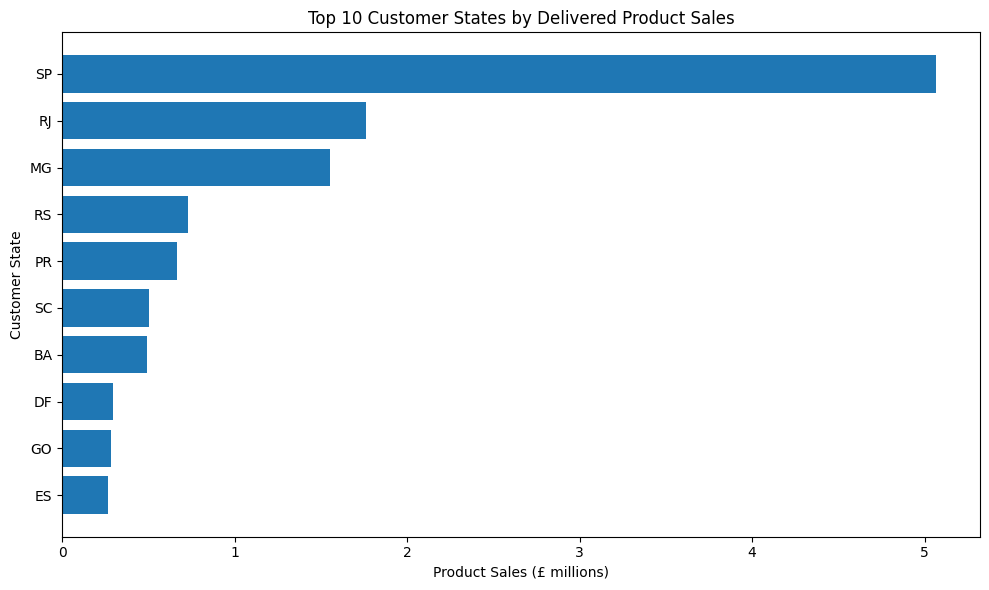

In [17]:
# Visualise top 10 customer states by delivered product sales

top_states = state_performance.head(10).copy()

top_states["sales_millions"] = (
    top_states["product_sales"] / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_states["customer_state"],
    top_states["sales_millions"]
)

plt.title("Top 10 Customer States by Delivered Product Sales")
plt.xlabel("Product Sales (£ millions)")
plt.ylabel("Customer State")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

### Geographical Sales Performance

The geographical analysis shows a strong concentration of delivered product sales in São Paulo (SP). Customers in SP generated approximately £5.07 million in product sales from 40,501 delivered orders. Rio de Janeiro (RJ) and Minas Gerais (MG) followed with approximately £1.76 million and £1.55 million respectively.

The results also show that SP has substantially more customers and orders than the other states. Therefore, its higher total sales should not automatically be interpreted as evidence that individual customers in SP spend more. The result primarily demonstrates where the largest volume of observed purchasing activity is located.

Customer state was used for this analysis because it provides a consistent geographical field across the transaction dataset. The results can support geographical filtering and comparison in the later Power BI dashboard.

In [18]:
# Calculate average product sales per delivered order by state

state_performance["average_sales_per_order"] = (
    state_performance["product_sales"]
    / state_performance["total_orders"]
).round(2)

print("Top 10 States by Total Product Sales")
print(
    state_performance[
        [
            "customer_state",
            "product_sales",
            "total_orders",
            "unique_customers",
            "average_sales_per_order"
        ]
    ].head(10)
)

Top 10 States by Total Product Sales
   customer_state  product_sales  total_orders  unique_customers  \
25             SP     5067633.16         40501             39156   
18             RJ     1759651.13         12350             11917   
10             MG     1552481.83         11354             11001   
22             RS      728897.47          5345              5168   
17             PR      666063.51          4923              4769   
23             SC      507012.13          3546              3449   
4              BA      493584.14          3256              3158   
6              DF      296498.41          2080              2019   
8              GO      282836.70          1957              1895   
7              ES      268643.45          1995              1928   

    average_sales_per_order  
25                   125.12  
18                   142.48  
10                   136.73  
22                   136.37  
17                   135.30  
23                   142.98  
4   

Further comparison supports this interpretation. SP generated an average of 125.12 in product sales per delivered order, which was lower than several other high-sales states. For example, BA averaged 151.59 per order, while GO, SC, DF and RJ were all above 142 per order. Therefore, SP's leading total sales position appears to be mainly associated with its much larger number of observed customers and orders rather than a higher product value per order.

In [19]:
# Analyse purchasing patterns by day of week

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_performance = (
    transactions
    .groupby("purchase_day_of_week")
    .agg(
        product_sales=("sales_value", "sum"),
        total_orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count")
    )
    .reindex(day_order)
    .reset_index()
)

weekday_performance["product_sales"] = (
    weekday_performance["product_sales"].round(2)
)

print(weekday_performance)

  purchase_day_of_week  product_sales  total_orders  items_sold
0               Monday     2168905.61         15701       17973
1              Tuesday     2122264.52         15503       17858
2            Wednesday     2051533.71         15076       17219
3             Thursday     1958600.49         14323       16434
4               Friday     1910496.12         13685       15698
5             Saturday     1464049.60         10555       11885
6               Sunday     1545648.06         11635       13130


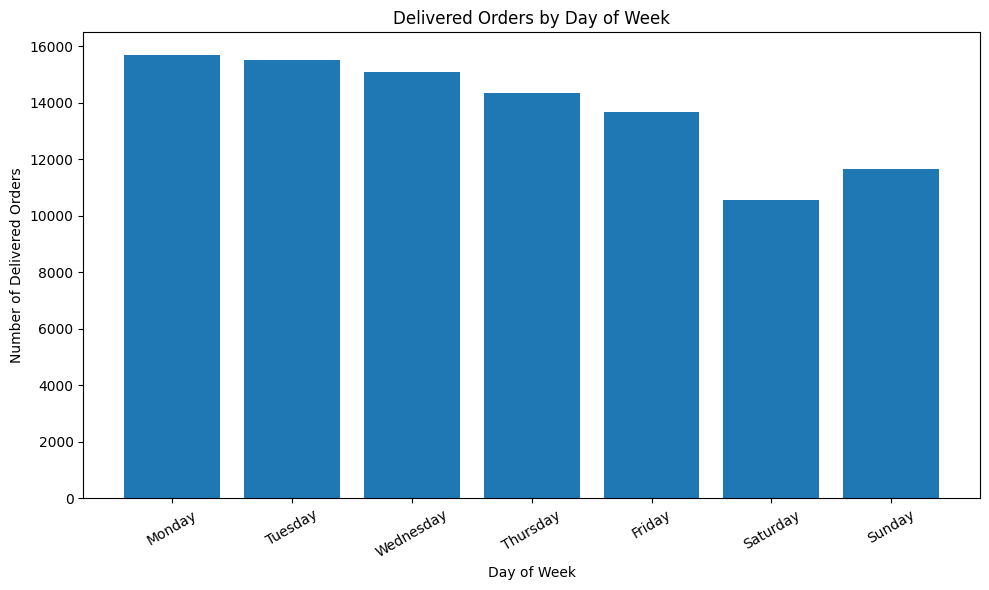

In [20]:
# Visualise delivered orders by day of week

plt.figure(figsize=(10, 6))

plt.bar(
    weekday_performance["purchase_day_of_week"],
    weekday_performance["total_orders"]
)

plt.title("Delivered Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Delivered Orders")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

### Purchasing Patterns by Day of Week

The day-of-week analysis shows that delivered purchasing activity was higher during weekdays than at the weekend. Monday recorded the highest number of delivered orders at 15,701, followed closely by Tuesday with 15,503. Order volumes then decreased across the remainder of the working week. Saturday recorded the lowest number of delivered orders at 10,555, while Sunday increased slightly to 11,635.

Product sales followed a similar general pattern, with Monday generating approximately 2.17 million in product sales compared with approximately 1.46 million on Saturday.

These results indicate that purchasing activity varies across the week within the observed dataset. However, the figures represent aggregate counts across the available period and do not by themselves establish the cause of the differences. The weekday pattern will be considered when preparing the data for sales forecasting and may also provide useful information for the final business intelligence dashboard.

In [21]:
# Analyse the number of items in each delivered order

order_size = (
    transactions
    .groupby("order_id")
    .agg(
        items_per_order=("order_item_id", "count"),
        order_product_value=("sales_value", "sum")
    )
    .reset_index()
)

print("Items per Delivered Order")
print("-------------------------")
print(order_size["items_per_order"].describe())

print("\nOrders with more than one item:")
multi_item_orders = (order_size["items_per_order"] > 1).sum()

print(multi_item_orders)
print(
    "Percentage:",
    round(multi_item_orders / len(order_size) * 100, 2),
    "%"
)

Items per Delivered Order
-------------------------
count    96478.000000
mean         1.142198
std          0.538804
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: items_per_order, dtype: float64

Orders with more than one item:
9635
Percentage: 9.99 %


### Delivered Order Size

The order-level analysis shows that most delivered orders contained only one item. The median was one item per order and 75% of orders also contained one item. Of the 96,478 delivered orders, 9,635 (9.99%) contained more than one item, meaning approximately 90% were single-item orders. The maximum observed order contained 21 items.

This indicates that multi-item purchasing was relatively uncommon within the available dataset. The result also demonstrates why order counts and item counts should be treated as separate measures in the analysis and Power BI dashboard, as 110,197 delivered items were associated with 96,478 delivered orders.

## Exploratory Data Analysis Summary

The exploratory analysis identified several important patterns within the prepared retail dataset. Delivered product sales increased substantially across the main observation period, although the sparse 2016 data means that the earliest months should be interpreted carefully. Product sales were concentrated across several leading categories, with health and beauty, watches and gifts, and bed, bath and table generating the highest sales values.

Customer behaviour showed particularly important characteristics. Most customers placed only one delivered order, with repeat customers representing approximately 3% of customers. Customer spending was strongly right-skewed, with a small number of customers accounting for substantially higher spending values. Most delivered orders also contained only one item.

Geographical analysis showed that São Paulo generated the largest total sales and order volume. However, its average product sales per order was lower than several other high-sales states, indicating that its leading position was mainly associated with a larger volume of customers and orders. Purchasing activity also varied across the week, with higher observed order volumes during weekdays and lower activity during the weekend.

These findings will inform the next stages of the project. In particular, the low variation in customer purchase frequency and the skewed spending distribution need to be considered when selecting and evaluating an appropriate customer segmentation method. The observed temporal patterns will also be considered when preparing the sales data for forecasting.